# ¿Sube o baja el dólar mañana? — Backtest de la estrategia USD/CLP

**Torneo de Trading FEN – Banco Itaú 2026 · Data Science en Finanzas**

Este notebook resume el backtest de la estrategia. Responde los cuatro puntos de la entrega:

1. **Cómo ejecutarlo**: celda siguiente y `README.md`.
2. **Resumen del backtest**: estadísticas de trading netas de carry y costos (retorno, volatilidad, Sharpe, drawdown máximo, % de aciertos, número de operaciones) y gráficos de la estrategia y sus retornos (secciones 4 a 6).
3. **Modelos y supuestos** (sección 2).
4. **Mecanismo de ejecución**: cuándo opera y qué gatilla cada operación (sección 3).

**Para ejecutarlo:** con la base del laboratorio en `data/raw/base_usdclp.xlsx`, abre este notebook desde la carpeta raíz del repositorio y usa *Kernel → Restart & Run All*. Si las predicciones no están calculadas, el notebook las genera: tarda unos 3 minutos, porque reentrena el modelo mes a mes desde 2008.

**Dos versiones:**
* **v2 (producción, la que opera en el monitoreo en vivo).**
* **v1 (oficial, pre-registrada antes de mirar 2023-2026).**

La v2 se diseñó después de conocer el resultado de la v1, y sus parámetros se eligieron solo con 2013-2022. El detalle está en `INFORME.md`, sección 9.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from usdclp import backtest as bt, config, entrega, features, plots, stats_tests, strategy

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
%matplotlib inline

## 1. Datos

La base es la entregada por el laboratorio: 66 series Bloomberg en formato ancho. Al construir las variables se respeta la disponibilidad de cada dato al momento de decidir (*point-in-time*):

* Los flujos de la banca publicados por el BCCh se usan con **2 jornadas de rezago**, y SOFR y Fed Funds con **1**.
* La macro se ubica en su **fecha de publicación**.
* Ningún dato se arrastra más de 5 jornadas.

El objetivo es el **retorno en exceso de carry** de una posición comprada en dólar, desde el cierre de *t* hasta el cierre de *t+1*.

In [2]:
df = features.build_dataset()
print(f"Calendario: jornadas del USD/CLP, {df.index.min().date()} a {df.index.max().date()} ({len(df):,} jornadas)")
print(f"Ultimo cierre USD/CLP: {df['px'].iloc[-1]:.2f} ({df.index.max().date()})")
(df[["px", "carry", "excess_next", "y"]].tail()
   .assign(carry=lambda d: d.carry * 1e4, excess_next=lambda d: d.excess_next * 1e4)
   .rename(columns={"px": "USDCLP cierre", "carry": "carry t->t+1 (pb)", "excess_next": "exceso t->t+1 (pb)",
                    "y": "sube en exceso (1/0)"}))

Calendario: jornadas del USD/CLP, 1990-01-01 a 2026-11-06 (9,316 jornadas)
Ultimo cierre USD/CLP: 978.50 (2026-11-06)


,USDCLP cierre,carry t->t+1 (pb),exceso t->t+1 (pb),sube en exceso (1/0)
fecha,,,,
2026-11-02,977.95,0.15,39.01,1.00
2026-11-03,981.78,0.15,-166.99,0.00
2026-11-04,965.40,0.15,142.07,1.00
2026-11-05,979.13,0.16,-6.59,0.00
2026-11-06,978.50,NaN,NaN,NaN


## 2. Modelos y supuestos

**Modelos.** Cada mes se reentrena con todo el historial anterior (desde 2005), con un embargo de 5 jornadas antes de predecir. Las observaciones antiguas pesan menos: un dato de hace 3 años pesa la mitad que uno de hoy.

| Pieza | Qué hace | Versión |
|---|---|---|
| **Regresión Ridge** | modelo lineal regularizado que predice el retorno del día siguiente medido en desvíos (exceso de carry ÷ volatilidad de 20 días, acotado a ±4) | v2 |
| **LightGBM regresor** (pérdida de Huber, 3 semillas) | lo mismo, pero capta no linealidades e interacciones | v2 |
| Regresión logística L2 | probabilidad de que el dólar suba en exceso de carry | v1 |
| LightGBM clasificador | lo mismo, con árboles | v1 |
| **Combinación** | promedio de los dos modelos de la versión, llevado a una probabilidad *p* de alza | ambas |
| **Calibración** (*temperature scaling*) | ajusta qué tan confiada es *p*, usando solo predicciones pasadas | ambas |

**Variables (31).** Retornos y volatilidad del propio USD/CLP, monedas pares (BRL, MXN, ZAR, canasta regional), dólar global (BBDXY), cobre (COMEX y LME), oro, VIX, S&P 500, volatilidad implícita del peso, tasas y swaps (diferencial Chile-EE.UU., base NDF), flujos de la banca y calendario.

**Supuestos clave.**
1. **Horario de decisión:** como indican las bases, los cierres de una misma fecha están disponibles al decidir. Eso incluye las series que cierran en Nueva York después del cierre de Santiago. **La ventaja del modelo depende de esa ventana**: rezagando esas series un día, la ventaja desaparece.
2. **Costo:** 4 pb por unidad de nocional transada, sobre el cambio de exposición. Es un supuesto conservador, y en la sección 4 se muestra la sensibilidad.
3. **Carry:** cámara promedio (CLICP) en pesos menos SOFR (Fed Funds antes de 2018) en dólares, Act/360. Comprado en dólar se paga; vendido se recibe.
4. **Nocional fijo:** el resultado acumulado es la suma de los retornos diarios.
5. **Selección de parámetros:** solo con 2013-2022. 2023-2026 es fuera de muestra.

## 3. Mecanismo de ejecución

**La estrategia opera al cierre.** No usa la apertura ni el dólar observado. El dólar observado publicado en *t* refleja la jornada *t−1*, así que se descarta para el retorno.

Cada jornada *t*, después del cierre de todas las series del día:

1. Se calcula la probabilidad de alza del modelo con los cierres de *t* y se **suaviza** con una media exponencial de 3 jornadas: *p*.
2. **Convicción** = |*p* − 0,5|.
3. Se decide la exposición, que se mantiene **del cierre de *t* al cierre de *t+1*** y se valoriza con `USDCLP Curncy|PX_LAST`. En orden:

| Condición | Exposición |
|---|---|
| Volatilidad realizada de 20 días sobre su **percentil 95** del último año (solo v2) | **0** (fuera) |
| Correlación entre las predicciones y los resultados de las últimas 250 jornadas (IC del modelo) ≤ 0: **compuerta cerrada** | **0** |
| Convicción bajo su **percentil 20** de las últimas 250 jornadas | **0** |
| Convicción en el **10% superior** **y** IC del modelo > 0,05 **y** volatilidad bajo su percentil 80 (este último solo en v2) | **±3** |
| En cualquier otro caso | **±1** |

El signo es + (comprado en dólar) si *p* > 0,5, y − (vendido) si *p* < 0,5.

**Qué gatilla una operación:** cualquier cambio de exposición respecto del día anterior (entrar, salir, invertir o cambiar de tamaño). Cada operación paga el costo sobre |cambio de exposición|. Todos los umbrales usan solo información anterior a la decisión.

**Para replicar en el monitor:** `reports/posiciones_v2.csv` trae, para cada jornada desde 2013, la probabilidad, los umbrales, el IC, la compuerta, el estado de volatilidad, la exposición y el motivo. En producción, `python scripts/senal_del_dia.py` aplica exactamente este procedimiento a la base actualizada.

## 4. Resumen del backtest

Predicciones walk-forward: cada mes se predice con un modelo entrenado solo con el pasado, así que todas las predicciones son fuera de muestra respecto de su propio entrenamiento.

In [3]:
pred = {v: entrega.get_predictions(df, kind) for v, (kind, _) in entrega.VERSIONS.items()}
P = {v: entrega.build_positions(df, pred[v], v) for v in entrega.VERSIONS}
pos = {"v2 (produccion)": P["v2"]["pos"], "v1 (oficial)": P["v1"]["pos"], **entrega.reference_positions(P["v1"])}
print("Predicciones hasta:", pred["v2"].index.max().date())

Predicciones hasta: 2026-11-06


### 4.1 Fuera de muestra: 2023-01-02 a 2026-10-05 (952 jornadas)

Estadísticas netas de carry y de 4 pb de costo. El % de aciertos se mide en las jornadas con posición abierta. Una operación es cada cambio de exposición.

In [4]:
oos = entrega.stats_table(df, pos, "Fuera de muestra 2023-2026")
entrega.show(oos)

,v2 (produccion),v1 (oficial),Comprar siempre,No operar nunca,Exposicion uno (signo del modelo)
Jornadas,952,952,952,952,952
Retorno neto total %,16.99,7.65,7.68,0.00,5.87
Retorno neto anual %,4.50,2.03,2.03,0.00,1.55
Retorno bruto anual % (antes de costos),11.33,8.54,2.04,0.00,10.14
Volatilidad anual %,14.53,14.24,12.80,0.00,12.82
Sharpe neto,0.31,0.14,0.16,-,0.12
Max drawdown %,-35.88,-38.80,-17.88,0.00,-39.70
% aciertos (dias con posicion),52.22,50.37,50.42,-,53.36
Numero de operaciones,438,424,1,0,406
Dias con posicion,653,667,952,0,952


### 4.2 Desarrollo (validación walk-forward 2013-2022) y seguimiento real posterior a la base original (oct-nov 2026)

In [5]:
dev = entrega.stats_table(df, pos, "Desarrollo 2013-2022")
seg = entrega.stats_table(df, pos, "Seguimiento oct-nov 2026")
print("Desarrollo 2013-2022"); display(entrega.show(dev))
print("Seguimiento 7-oct a 6-nov-2026 (22 jornadas)"); display(entrega.show(seg))

Desarrollo 2013-2022


,v2 (produccion),v1 (oficial),Comprar siempre,No operar nunca,Exposicion uno (signo del modelo)
Jornadas,"2,511","2,511","2,511","2,511","2,511"
Retorno neto total %,184.25,149.35,40.73,0.00,91.37
Retorno neto anual %,18.49,14.99,4.09,0.00,9.17
Retorno bruto anual % (antes de costos),26.02,21.83,4.09,0.00,17.75
Volatilidad anual %,13.50,13.76,12.08,0.00,12.07
Sharpe neto,1.37,1.09,0.34,-,0.76
Max drawdown %,-13.91,-31.11,-26.01,0.00,-29.99
% aciertos (dias con posicion),54.36,54.49,50.34,-,53.64
Numero de operaciones,"1,259","1,174",1,0,"1,069"
Dias con posicion,"1,856","1,861","2,511",0,"2,511"


Seguimiento 7-oct a 6-nov-2026 (22 jornadas)


,v2 (produccion),v1 (oficial),Comprar siempre,No operar nunca,Exposicion uno (signo del modelo)
Jornadas,22,22,22,22,22
Retorno neto total %,-1.28,-0.76,0.43,0.00,-2.14
Retorno neto anual %,-14.63,-8.73,4.93,0.00,-24.51
Retorno bruto anual % (antes de costos),-5.00,-3.23,5.39,0.00,-14.88
Volatilidad anual %,7.96,10.33,11.50,0.00,11.34
Sharpe neto,-1.84,-0.85,0.43,-,-2.16
Max drawdown %,-2.18,-1.97,-3.01,0.00,-2.78
% aciertos (dias con posicion),47.06,54.55,59.09,-,40.91
Numero de operaciones,16,12,1,0,11
Dias con posicion,17,11,22,0,22


### 4.3 Sensibilidad al costo de transacción (fuera de muestra, retorno neto anual %)

In [6]:
sl = slice(config.OOS_START, config.OOS_END)
sens = pd.DataFrame({f"{c:g} pb": {k: bt.metrics(bt.run(p.loc[sl], df["excess_next"], c))["retorno_anual_%"]
                                     for k, p in pos.items()} for c in (0, 2, 4, 6, 10)})
sens

,0 pb,2 pb,4 pb,6 pb,10 pb
v2 (produccion),11.33,7.91,4.50,1.08,-5.75
v1 (oficial),8.54,5.28,2.03,-1.23,-7.74
Comprar siempre,2.04,2.04,2.03,2.03,2.02
No operar nunca,0.00,0.00,0.00,0.00,0.00
Exposicion uno (signo del modelo),10.14,5.85,1.55,-2.74,-11.33


## 5. Gráficos de la estrategia y sus retornos

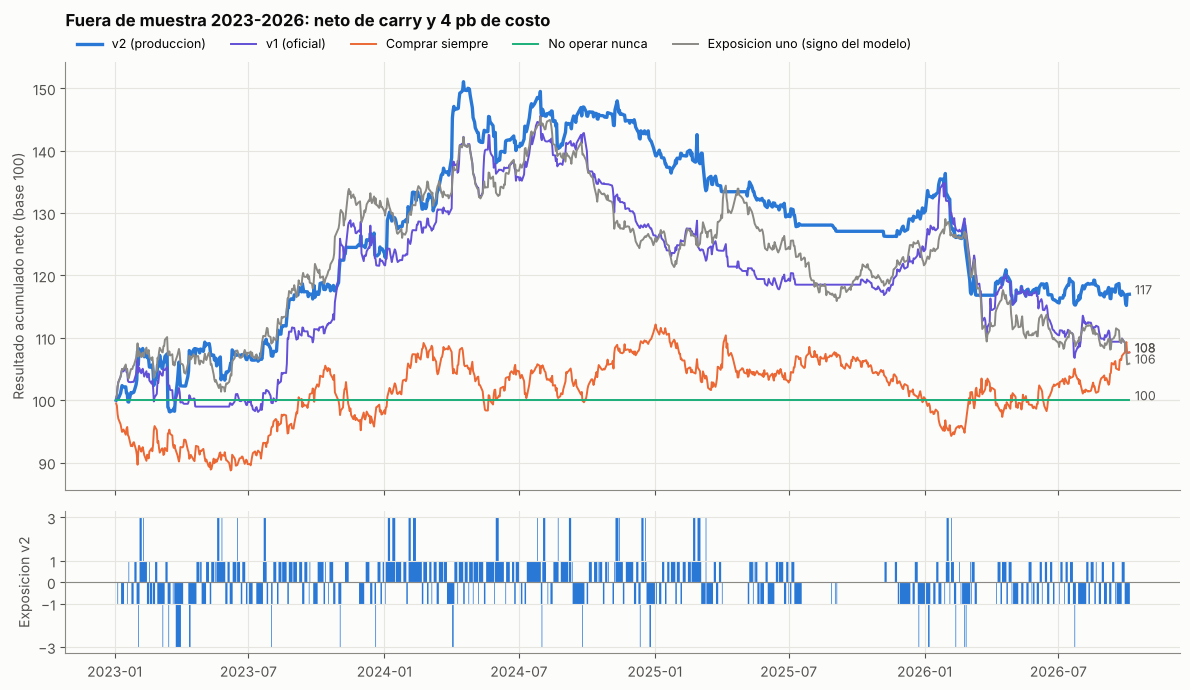

In [7]:
def curvas(period, titulo):
    start, end = entrega.PERIODS[period]
    end = end or df["excess_next"].dropna().index.max()
    sl = slice(start, end)
    runs = {k: bt.run(p.loc[sl], df["excess_next"]) for k, p in pos.items()}
    colors = [plots.BLUE, plots.VIOLET, plots.ORANGE, plots.AQUA, plots.MUTED]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    a1.axhline(100, color=plots.GRID, lw=0.8, zorder=0)
    for (k, r), c in zip(runs.items(), colors):
        eq = bt.equity_curve(r)
        a1.plot(eq.index, eq.values, color=c, lw=2.4 if c == plots.BLUE else 1.4, label=k)
        a1.annotate(f"{eq.iloc[-1]:.0f}", (eq.index[-1], eq.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, color=plots.INK2)
    a1.set_ylabel("Resultado acumulado neto (base 100)")
    a1.set_title(titulo, loc="left", pad=26)
    a1.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5, fontsize=9)
    a2.fill_between(runs["v2 (produccion)"].index, 0, runs["v2 (produccion)"]["pos"], step="post", color=plots.BLUE, lw=0)
    a2.set_yticks([-3, -1, 0, 1, 3]); a2.set_ylabel("Exposicion v2"); a2.axhline(0, color=plots.MUTED, lw=0.8)
    plt.tight_layout(); plt.show()

curvas("Fuera de muestra 2023-2026", "Fuera de muestra 2023-2026: neto de carry y 4 pb de costo")

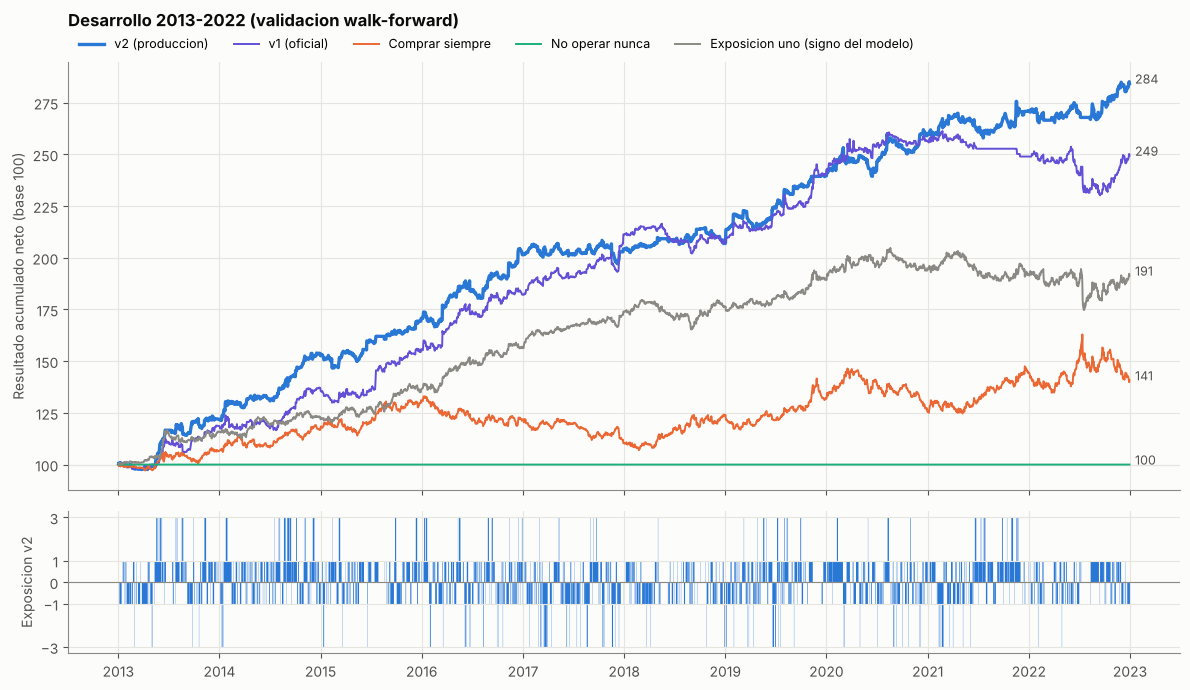

In [8]:
curvas("Desarrollo 2013-2022", "Desarrollo 2013-2022 (validacion walk-forward)")

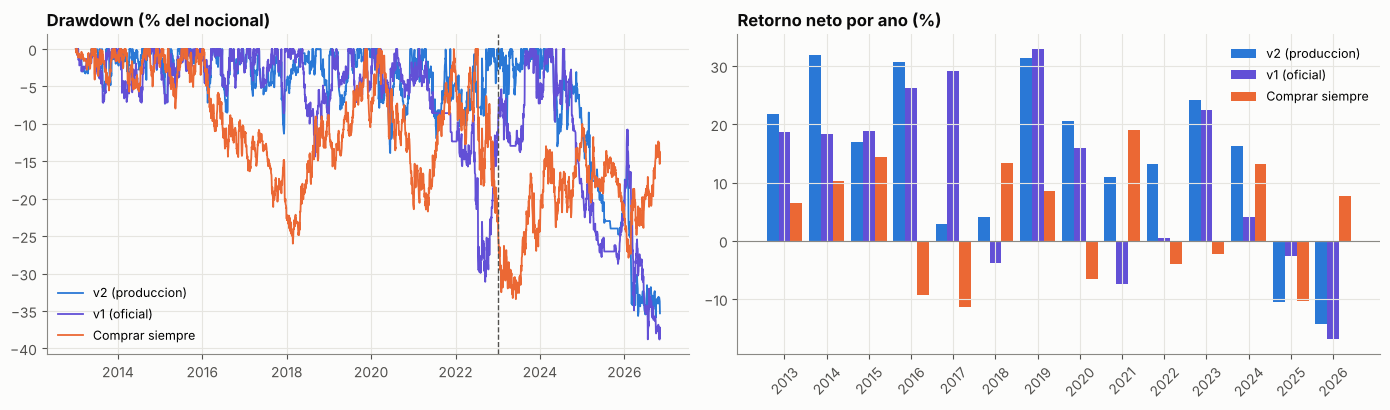

fecha,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
v2 (produccion),21.80,31.90,17.00,30.70,2.80,4.00,31.40,20.50,10.90,13.10,24.20,16.20,-10.50,-14.30
v1 (oficial),18.70,18.40,18.80,26.20,29.20,-3.80,32.90,15.90,-7.40,0.40,22.40,4.10,-2.60,-16.90
Comprar siempre,6.50,10.30,14.40,-9.40,-11.40,13.30,8.50,-6.50,19.00,-3.90,-2.20,13.10,-10.40,7.70


In [9]:
full = slice(config.VAL_START, df["excess_next"].dropna().index.max())
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for k, c in [("v2 (produccion)", plots.BLUE), ("v1 (oficial)", plots.VIOLET), ("Comprar siempre", plots.ORANGE)]:
    r = bt.run(pos[k].loc[full], df["excess_next"])["net"]
    eq = r.cumsum() * 100
    axs[0].plot((eq - eq.cummax()).index, (eq - eq.cummax()).values, color=c, lw=1.3, label=k)
axs[0].axvline(pd.Timestamp(config.OOS_START), color=plots.INK2, ls="--", lw=1)
axs[0].set_title("Drawdown (% del nocional)", loc="left"); axs[0].legend(loc="lower left", fontsize=9)

yr = pd.DataFrame({k: bt.run(pos[k].loc[full], df["excess_next"])["net"].groupby(lambda d: d.year).sum() * 100
                   for k in ["v2 (produccion)", "v1 (oficial)", "Comprar siempre"]})
x = np.arange(len(yr)); w = 0.28
for i, (k, c) in enumerate([("v2 (produccion)", plots.BLUE), ("v1 (oficial)", plots.VIOLET), ("Comprar siempre", plots.ORANGE)]):
    axs[1].bar(x + (i - 1) * w, yr[k].values, width=w, color=c, label=k)
axs[1].set_xticks(x); axs[1].set_xticklabels(yr.index, rotation=45); axs[1].axhline(0, color=plots.MUTED, lw=0.8)
axs[1].set_title("Retorno neto por ano (%)", loc="left"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
yr.round(1).T

## 6. Lectura de la convicción (v2, fuera de muestra)

¿Rinden más las jornadas en que la estrategia arriesga más? La tabla mide la ventaja de la señal (con exposición 1) según el nivel de exposición que eligió la regla, y el motivo de cada decisión.

In [10]:
sl = slice(config.OOS_START, config.OOS_END)
Q = P["v2"].loc[sl].copy()
r = bt.run(Q["pos"], df["excess_next"])
Q["ret"] = df["excess_next"].reindex(Q.index)
Q["senal_x1"] = np.sign(Q["edge"]) * Q["ret"]
Q["neto"] = r["net"]
Q["nivel"] = Q["pos"].abs().map({0: "0 (fuera)", 1: "1", 3: "3 (maxima)"})
Q["motivo"] = [entrega.motivo(row) for _, row in Q.assign(conv_big=False).iterrows()]
tabla = Q.groupby("nivel").agg(jornadas=("neto", "size"), acierto_senal_pct=("senal_x1", lambda s: (s > 0).mean() * 100),
                               ventaja_senal_pb_dia=("senal_x1", lambda s: s.mean() * 1e4),
                               resultado_neto_pct=("neto", lambda s: s.sum() * 100))
display(tabla)
Q["motivo"].value_counts().to_frame("jornadas")

,jornadas,acierto_senal_pct,ventaja_senal_pb_dia,resultado_neto_pct
nivel,,,,
0 (fuera),299,53.51,4.33,-5.80
1,598,51.84,7.31,27.62
3 (maxima),55,56.36,-0.55,-4.83


,jornadas
motivo,
x1: conviccion sobre el umbral,598
fuera: conviccion bajo el umbral,168
fuera: compuerta cerrada (IC del modelo <= 0),81
"x3: conviccion en el 10% superior y IC > 0,05",55
fuera: volatilidad extrema (> p95),50


## 7. Significancia estadística (v2, fuera de muestra)

* **Diebold-Mariano:** pérdida = −retorno neto diario, con corrección de Harvey-Leybourne-Newbold y varianza Newey-West.
* **Bootstrap estacionario** (Politis-Romano), con bloque medio de 10 días.

H1: la v2 rinde más que la referencia.

In [11]:
sl = slice(config.OOS_START, config.OOS_END)
runs = {k: bt.run(p.loc[sl], df["excess_next"])["net"] for k, p in pos.items()}
rows = {}
for ref in ["Comprar siempre", "No operar nunca", "Exposicion uno (signo del modelo)", "v1 (oficial)"]:
    d = stats_tests.diebold_mariano(-runs["v2 (produccion)"], -runs[ref])
    b = stats_tests.bootstrap_test(runs["v2 (produccion)"], runs[ref], n_boot=2000)
    rows[f"v2 vs {ref}"] = {"dif. retorno anual %": b["dif_retorno_anual_%"], "DM": d["DM"], "p DM": d["p_valor_una_cola"],
                            "p bootstrap": b["p_valor_dif_retorno"]}
display(pd.DataFrame(rows).T)
ab = stats_tests.alpha_beta(runs["v2 (produccion)"], runs["Comprar siempre"])
print(f"Alfa anual {ab['alfa_anual_%']:.2f}% (t = {ab['t_alfa']:.2f}) | beta contra comprar siempre {ab['beta']:.2f} (t = {ab['t_beta']:.2f})")

,dif. retorno anual %,DM,p DM,p bootstrap
v2 vs Comprar siempre,2.46,0.23,0.41,0.39
v2 vs No operar nunca,4.50,0.57,0.28,0.28
v2 vs Exposicion uno (signo del modelo),2.94,0.41,0.34,0.33
v2 vs v1 (oficial),2.47,0.41,0.34,0.33


Alfa anual 4.87% (t = 0.63) | beta contra comprar siempre -0.18 (t = -2.23)


## 8. Señal del día (producción)

La última decisión disponible con la base actual, tal como la emite `scripts/senal_del_dia.py`.

In [12]:
last = P["v2"].index.max()
row = P["v2"].loc[last]
lectura = {0: "fuera del mercado (en pesos)", 1: "comprado 1x", 3: "comprado 3x", -1: "vendido 1x", -3: "vendido 3x"}[int(row["pos"])]
print(f"Decision al cierre del {last.date()} (USD/CLP {df.loc[last, 'px']:.2f}) para la jornada siguiente:")
print(f"  probabilidad de alza (suavizada): {row['p']:.4f}  ->  direccion esperada: {'sube' if row['edge'] > 0 else 'baja'}")
print(f"  conviccion |p-0.5| = {abs(row['edge']):.4f} | umbral abstencion {row['t1']:.4f} | umbral x3 {row['t_big']:.4f}")
print(f"  IC del modelo (250 jornadas) = {row['model_ic']:.3f} | compuerta {'abierta' if row['gate'] else 'cerrada'} | estado vol {int(row['vol_state'])}")
print(f"  POSICION SUGERIDA: {int(row['pos'])}  ({lectura}) -> {entrega.motivo(row.to_dict() | {'conv_big': False})}")

Decision al cierre del 2026-11-06 (USD/CLP 978.50) para la jornada siguiente:
  probabilidad de alza (suavizada): 0.5122  ->  direccion esperada: sube
  conviccion |p-0.5| = 0.0122 | umbral abstencion 0.0044 | umbral x3 0.0286
  IC del modelo (250 jornadas) = 0.042 | compuerta abierta | estado vol 0
  POSICION SUGERIDA: 1  (comprado 1x) -> x1: conviccion sobre el umbral


## 9. Conclusiones

* **Desarrollo 2013-2022:** la v2 rinde **+18,5% anual neto** (Sharpe 1,37) y es positiva los 10 años.
* **Fuera de muestra 2023-2026:** **+4,5% anual neto** (Sharpe 0,31), más del doble que comprar siempre (+2,0%) y que la v1 (+2,0%). El resultado se concentra en 2023-2024. En 2025-2026 pierde, por un cambio en la microestructura del cierre del peso (ver `INFORME.md`, sección 6).
* **Las diferencias no son estadísticamente significativas fuera de muestra:** lo reportamos así, sin maquillaje. El control nulo con etiquetas barajadas da ventaja cero, así que el pipeline no fabrica señal.
* **Convicción.** En la v2, fuera de muestra, la ventaja de la señal está en las jornadas de exposición 1 (+7,3 pb/día). Las 55 jornadas de exposición ±3 no agregaron valor (−0,6 pb/día), a diferencia de la v1, donde rindieron +16 pb/día. La regla de ×3 es exigente (convicción alta, modelo acertando y volatilidad no alta), y lo reportamos tal cual.
* **Costos:** a 2 pb la v2 rinde 7,9% anual fuera de muestra; a 6 pb, 1,1%. El costo oficial del laboratorio determina el resultado final.